# Recorded jacket potentials → epicardial potential

This complete author demonstration contains191recorded outer potentials and nested heart/tank geometry, with247desired sock locations. Sample identity and absolute voltage calibration are unspecified: values remain in the **native potential unit**, not guessed millivolts. The original author method is a **numerical reference**, not cardiac ground truth. Original source/data licensing is unverified; this internal research package independently implements the equations and requires permission review before external distribution.

In [1]:
from pathlib import Path
import sys,time,json,numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').exists():root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct,ridge_coefficients
from src.physics_model import evaluate_potential
from src.visualization import make_figures,rms
data=load_data(root/'data/raw_data.npz')
print({k:(v.shape,str(v.dtype)) for k,v in data.items()})

{'heart_vertices': ((337, 3), 'float64'), 'heart_faces': ((670, 3), 'int64'), 'torso_vertices': ((284, 3), 'float64'), 'torso_faces': ((564, 3), 'int64'), 'sock_vertices': ((247, 3), 'float64'), 'electrode_indices': ((191,), 'int64'), 'potentials': ((1, 191), 'float64')}


## Physics and complete selected method

The homogeneous source-free region between the heart and outer surface obeys ∇²φ=0, with measured φ and zero outward normal derivative on the insulating jacket. Write φ=a0+Σaj/(4π|x−ξj|). Each virtualsourceξ lies outside that region: innerpoints moveinward andouterpoints outward alongangle-weightednormals by.1times eachsurfaceboundingboxdiagonal. Bothmeshes areclosed/outwardoriented; independentwindingtestsconfirm sourceexclusion.

This Johnston/Tate variant differs from the2006paper's radialscaling. Forx measured numerically inmm,L0=1mm defines the relative potential/derivative weighting: A=[1 K;0 D],b=[y;0], withD=−dot(x−ξ,n)/(4π|x−ξ|³). ThinSVD givesa=V diag[s/(s²+λ²)]Uᵀb, penalizingallcoefficientsincludinga0. Chooseλ by the completeoriginalCRESOmaximum over10000linearlyspacedvalues1e-8..0.001, where C(λ)=Σs²α²(s²−3λ²)/(s²+λ²)³ andα=Uᵀb. No virtualsourcecoefficients are interpreted as physical charges. Onlyphi at247sockpositions is theunknownoutput.

In [2]:
start=time.perf_counter()
fresh=reconstruct(data)
print('Fresh full benchmark seconds',time.perf_counter()-start,'selected lambda',fresh['selected_lambda'])
reference=np.load(root/'notebooks/reference_outputs/original_method.npz')
original=reference['reconstruction']
print('All191 sensor RMS',rms(fresh['predicted_cauchy'][:191]-data['potentials'].ravel()),'native potential unit')
print('All191 normal derivative RMS',rms(fresh['predicted_cauchy'][191:]),'native potential unit/mm')

Fresh full benchmark seconds 0.10185599990654737 selected lambda 1.81016201620162e-06
All191 sensor RMS 0.0005953170627382556 native potential unit
All191 normal derivative RMS 0.0030911873497523 native potential unit/mm


## Fresh regularization comparison and numerical fidelity

Computeall247targetvalues for0.1×,1×and10×selectedλ using the same completeCauchyoperator. This is an explicit fresh regularizationcomparison, not alternativephysicaltruth. The dramaticattenuationofsmall singularvalues explains why a good outerfit alone cannot establishuniqueness or physiologicalaccuracy.

{
  "ncc": 1.0000000000000002,
  "nrmse": 7.712530106746817e-14,
  "max_abs_error": 4.259703700881801e-12
}


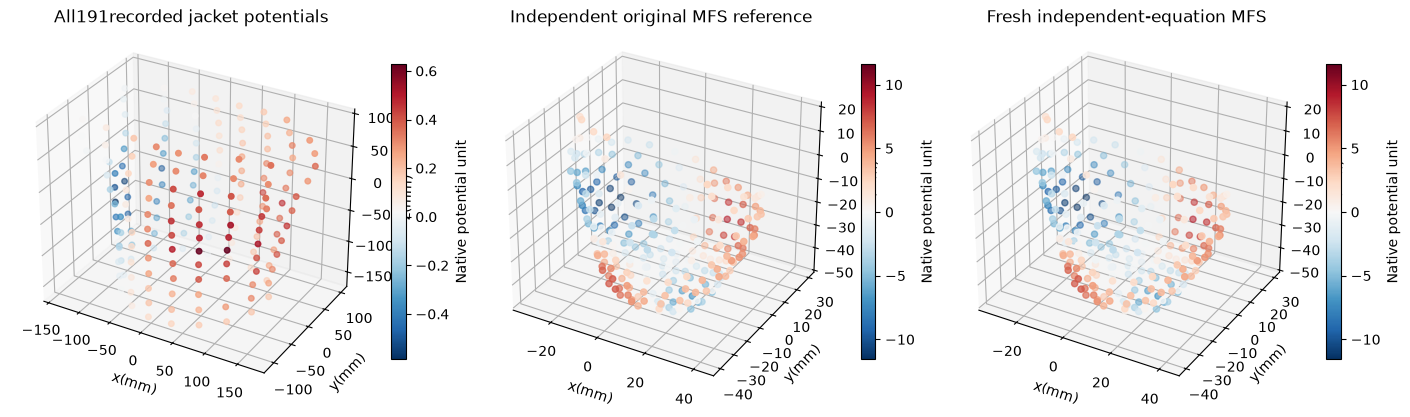

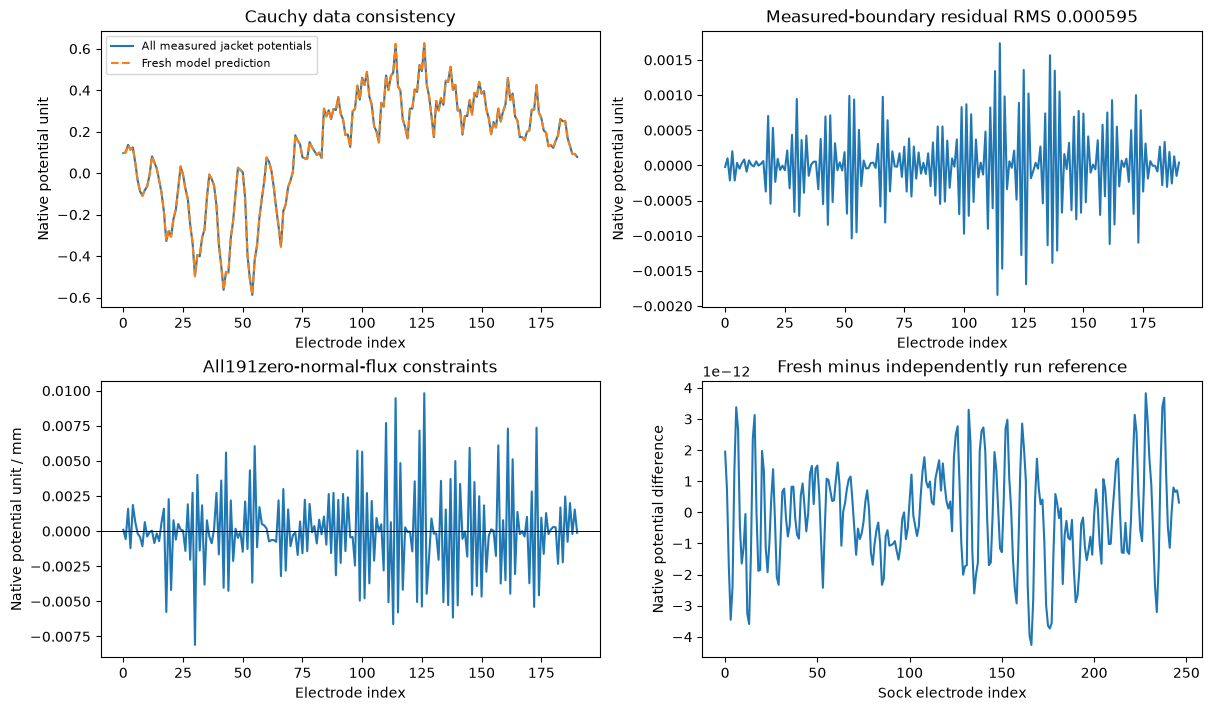

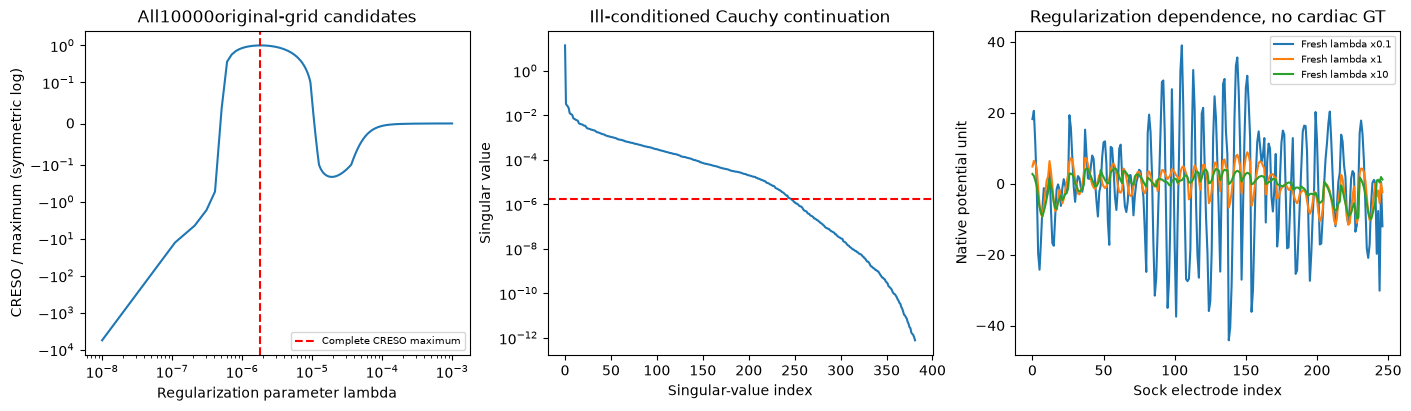

In [3]:
u,s,vt=np.linalg.svd(fresh['operator'],full_matrices=False)
sensitivity={}
for factor in [.1,1.,10.]:
    coef=ridge_coefficients(u,s,vt,fresh['rhs'],fresh['selected_lambda']*factor)
    sensitivity[factor]=evaluate_potential(data['sock_vertices'],fresh['sources'],coef)
import importlib.util
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
print(json.dumps(judge.score(fresh['reconstruction'],original),indent=2))
for figure in make_figures(data,fresh,original,sensitivity):plt.show()

## Conclusion and limitations

The fresh independently written mathematical implementation reproduces the originalauthor's completeCRESO MFS variant, all191observations andall247targets. The shownboundaryresiduals,fullsingularspectrumandfreshλcomparisonexposeill-conditioning ratherthan declaringa uniquely identifiedcardiacmap. The nativepotentialreferenceoffsetis preserved. Unknownsample,unknownabsolutecalibration,homogeneousvolumeapproximationandsource/dataauthorizationremainexplicitlimits. The olderexample.outcachehasdifferentfixedsourcedisplacements/unknownλ andis neitherselectedmethodreference nortruth.